# Ablation  — DF-SA-MRFO-SAINT-DeepFM-GF

## Imports and setup

In [ ]:
import os, json, time, math, random, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from scipy.stats import mannwhitneyu

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.family": "DejaVu Sans"})

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = "ablation_results"
os.makedirs(OUT_DIR, exist_ok=True)
print("Device:", DEVICE, "| PyTorch", torch.__version__)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, name), bbox_inches="tight")
    plt.show()

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

Device: cuda | PyTorch 2.11.0+cu130


## Configuration


In [ ]:
TARGET       = "Pregnancy_Outcome"
FINAL_EPOCHS = 50
RES_ALPHA    = 0.10
TAU          = 0.5
EPS_CLIP     = 1e-7
# hyperparameter configurations
MANUAL_HPARAMS   = dict(lr=0.0010, emb_dim=32, n_blocks=3, n_heads=4, fm_hidden=128, dropout=0.20, batch_size=128, l2=1e-3)
MRFO_HPARAMS     = dict(lr=0.0011, emb_dim=64, n_blocks=3, n_heads=4, fm_hidden=192, dropout=0.25, batch_size=160, l2=3e-4)
DFSAMRFO_HPARAMS = dict(lr=0.0008, emb_dim=64, n_blocks=4, n_heads=4, fm_hidden=256, dropout=0.30, batch_size=128, l2=1e-4)

EXPERIMENTS = [
    ("saint",    "SAINT",                          "saint",  MANUAL_HPARAMS),
    ("concat",   "SAINT + DeepFM",                 "concat", MANUAL_HPARAMS),
    ("mean",     "Averaging",                      "mean",   MANUAL_HPARAMS),
    ("fixed",    "Fixed learned weight",           "fixed",  MANUAL_HPARAMS),
    ("gate",     "SAINT + DeepFM + GF",            "gate",   MANUAL_HPARAMS),
    ("mrfo",     "SAINT + DeepFM + GF + MRFO",     "gate",   MRFO_HPARAMS),
    ("dfsamrfo", "SAINT + DeepFM + GF + DF-SA-MRFO", "gate", DFSAMRFO_HPARAMS),
]
RUN_KEYS = [e[0] for e in EXPERIMENTS]
GATE_MODEL_KEY = "gate"

## Data upload

In [ ]:
try:
    from google.colab import files
    uploaded = files.upload()
    DATA_PATH = list(uploaded.keys())[0]
except ImportError:
    DATA_PATH = "pregnancy_prediction_dataset.csv"

df = pd.read_csv(DATA_PATH) if DATA_PATH.lower().endswith(".csv") else pd.read_excel(DATA_PATH)
df.columns = [c.strip() for c in df.columns]
print("Shape:", df.shape)

# drop identifier-like columns
id_like = [c for c in df.columns if c.lower() in ("id", "patient_id", "patientid", "record_id", "unnamed: 0")]
df = df.drop(columns=id_like)
print("Dropped identifier columns:", id_like)

# encode the target as 1 = Pregnant, 0 = Not Pregnant
if not pd.api.types.is_numeric_dtype(df[TARGET]):
    t = df[TARGET].astype(str).str.strip().str.lower()
    df[TARGET] = t.map(lambda v: 0 if ("not" in v or v in ("0", "no", "negative")) else 1).astype(int)
CLASS_NAMES = ["Not Pregnant", "Pregnant"]
print(df[TARGET].value_counts().rename(index={0: "Not Pregnant (0)", 1: "Pregnant (1)"}))

Saving Pregnancy_Prediction.csv to Pregnancy_Prediction.csv
Shape: (50000, 41)
Dropped identifier columns: []
Pregnancy_Outcome
Pregnant (1)        34404
Not Pregnant (0)    15596
Name: count, dtype: int64


## Stratified 70:15:15 partitioning

In [ ]:
X_all = df.drop(columns=[TARGET])
y_all = df[TARGET].values.astype(int)

X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

split_tbl = pd.DataFrame({
    "Subset": ["Training", "Validation", "Testing"],
    "Records": [len(y_train), len(y_val), len(y_test)],
    "Not Pregnant (0)": [(y_train == 0).sum(), (y_val == 0).sum(), (y_test == 0).sum()],
    "Pregnant (1)": [(y_train == 1).sum(), (y_val == 1).sum(), (y_test == 1).sum()]})
print(split_tbl.to_string(index=False))

    Subset  Records  Not Pregnant (0)  Pregnant (1)
  Training    35000             10917         24083
Validation     7500              2339          5161
   Testing     7500              2340          5160


## Leakage-free preprocessing


In [ ]:
print("Missing values in the complete dataset:", int(df.isna().sum().sum()))
print("Exact duplicate records:", int(df.duplicated().sum()))

MULTI_CAT_HINTS = ["exercise", "stress", "diet"]

num_cols, bin_cols, cat_cols = [], [], []
for c in X_train_raw.columns:
    s = X_train_raw[c]
    nun = s.dropna().nunique()
    if not pd.api.types.is_numeric_dtype(s):
        (bin_cols if nun <= 2 else cat_cols).append(c)
    elif any(h in c.lower() for h in MULTI_CAT_HINTS) and nun <= 10:
        cat_cols.append(c)
    elif nun <= 2:
        bin_cols.append(c)
    else:
        num_cols.append(c)
print(f"Continuous: {len(num_cols)} | Binary: {len(bin_cols)} | Multi-category: {len(cat_cols)}")
print("Multi-category columns:", cat_cols)

class TabularPreprocessor:
    def fit(self, X):
        self.medians = X[num_cols].median()
        self.bin_maps, self.bin_modes = {}, {}
        for c in bin_cols:
            vals = sorted(X[c].dropna().unique(), key=lambda v: str(v))
            pos = [v for v in vals if str(v).strip().lower() in ("1", "1.0", "yes", "true", "y", "present", "positive")]
            if pos:
                self.bin_maps[c] = {v: (1 if v in pos else 0) for v in vals}
            else:
                self.bin_maps[c] = {v: i for i, v in enumerate(vals)}
            self.bin_modes[c] = X[c].mode().iloc[0]
        self.cat_modes = {c: X[c].mode().iloc[0] for c in cat_cols}
        self.cat_vocab = {c: {v: i for i, v in enumerate(sorted(X[c].dropna().unique(), key=lambda v: str(v)))}
                          for c in cat_cols}
        Xn = X[num_cols].fillna(self.medians).astype(float)
        self.mu, self.sigma = Xn.mean(), Xn.std(ddof=0)
        return self

    def raw_imputed(self, X):
        out = pd.DataFrame(index=X.index)
        for c in num_cols: out[c] = X[c].fillna(self.medians[c]).astype(float)
        for c in bin_cols: out[c] = X[c].fillna(self.bin_modes[c]).map(self.bin_maps[c]).fillna(0).astype(float)
        for c in cat_cols:
            out[c] = X[c].fillna(self.cat_modes[c]).map(self.cat_vocab[c]).fillna(len(self.cat_vocab[c])).astype(float)
        return out

    def transform(self, X):
        R = self.raw_imputed(X)
        x_num = ((R[num_cols] - self.mu) / (self.sigma + 1e-8)).values if num_cols else np.zeros((len(X), 0))
        x_bin = R[bin_cols].values if bin_cols else np.zeros((len(X), 0))
        x_cont = np.hstack([x_num, x_bin]).astype(np.float32)
        x_cat = R[cat_cols].values.astype(np.int64) if cat_cols else np.zeros((len(X), 0), np.int64)
        return x_cont, x_cat

prep = TabularPreprocessor().fit(X_train_raw)
Xc_tr, Xk_tr = prep.transform(X_train_raw)
Xc_va, Xk_va = prep.transform(X_val_raw)
Xc_te, Xk_te = prep.transform(X_test_raw)

CAT_CARDINALITIES = [len(prep.cat_vocab[c]) + 1 for c in cat_cols]
print("Continuous tensor:", Xc_tr.shape, "| Categorical tensor:", Xk_tr.shape)

# class weights: w_c = N / (K * N_c)
N_tr, K = len(y_train), 2
CLASS_W = torch.tensor([N_tr / (K * (y_train == c).sum()) for c in (0, 1)], dtype=torch.float32)
print("Class weights  w0 = %.4f, w1 = %.4f" % tuple(CLASS_W.tolist()))

Missing values in the complete dataset: 0
Exact duplicate records: 0
Continuous: 26 | Binary: 11 | Multi-category: 3
Multi-category columns: ['Exercise_Level', 'Stress_Level', 'Diet_Quality']
Continuous tensor: (35000, 37) | Categorical tensor: (35000, 3)
Class weights  w0 = 1.6030, w1 = 0.7267


## Ablation models


In [ ]:
class FeatureTokenizer(nn.Module):
    """Numeric projection e = x·w_j + b_j and categorical embedding lookup e = E_j[x]."""
    def __init__(self, n_cont, cat_cards, d):
        super().__init__()
        self.n_cont = n_cont
        self.w = nn.Parameter(torch.randn(n_cont, d) * 0.02)
        self.b = nn.Parameter(torch.zeros(n_cont, d))
        self.cat_emb = nn.ModuleList([nn.Embedding(k, d) for k in cat_cards])
    def forward(self, x_cont, x_cat):
        tok = [x_cont.unsqueeze(-1) * self.w + self.b] if self.n_cont else []
        if len(self.cat_emb):
            tok.append(torch.stack([emb(x_cat[:, j]) for j, emb in enumerate(self.cat_emb)], dim=1))
        return torch.cat(tok, dim=1)                                    # (B, p, d)

class SAINTBlock(nn.Module):
    """Feature-wise MHA -> inter-sample MHA -> residual + LN -> FFN + LN."""
    def __init__(self, p, d, heads, dropout):
        super().__init__()
        self.feat_attn = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.row_proj_in = nn.Linear(p * d, d)
        self.row_attn = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.row_proj_out = nn.Linear(d, p * d)
        self.ln1 = nn.LayerNorm(d); self.ln2 = nn.LayerNorm(d)
        self.ffn = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(4 * d, d))
        self.drop = nn.Dropout(dropout)
    def forward(self, H):
        B, p, d = H.shape
        Hf, _ = self.feat_attn(H, H, H)
        r = self.row_proj_in(Hf.reshape(B, p * d)).unsqueeze(0)
        Zr, _ = self.row_attn(r, r, r)
        Hr = Hf + self.row_proj_out(Zr.squeeze(0)).reshape(B, p, d)
        U = self.ln1(H + self.drop(Hr))
        return self.ln2(U + self.drop(self.ffn(U)))

class SAINTBranch(nn.Module):
    def __init__(self, n_cont, cat_cards, d, n_blocks, heads, dropout):
        super().__init__()
        p = n_cont + len(cat_cards)
        self.tok = FeatureTokenizer(n_cont, cat_cards, d)
        self.col_emb = nn.Parameter(torch.randn(1, p, d) * 0.02)
        self.blocks = nn.ModuleList([SAINTBlock(p, d, heads, dropout) for _ in range(n_blocks)])
        self.out_dim = d
    def forward(self, x_cont, x_cat):
        H = self.tok(x_cont, x_cat) + self.col_emb
        for blk in self.blocks: H = blk(H)
        return H.mean(dim=1)                                            # h_S = Pool(H)

class DeepFMBranch(nn.Module):
    """First-order + FM second-order + deep MLP; h_D = Concat(y1, y2, h_deep)."""
    def __init__(self, n_cont, cat_cards, d, hidden, dropout):
        super().__init__()
        p = n_cont + len(cat_cards)
        self.tok = FeatureTokenizer(n_cont, cat_cards, d)
        self.lin_cont = nn.Linear(n_cont, 1) if n_cont else None
        self.lin_cat = nn.ModuleList([nn.Embedding(k, 1) for k in cat_cards])
        self.mlp = nn.Sequential(nn.Linear(p * d, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(hidden, hidden // 2), nn.BatchNorm1d(hidden // 2), nn.ReLU(), nn.Dropout(dropout))
        self.out_dim = 2 + hidden // 2
    def forward(self, x_cont, x_cat):
        B = x_cont.shape[0]
        y1 = self.lin_cont(x_cont) if self.lin_cont is not None else torch.zeros(B, 1, device=x_cont.device)
        for j, emb in enumerate(self.lin_cat): y1 = y1 + emb(x_cat[:, j])
        V = self.tok(x_cont, x_cat)
        y2 = 0.5 * (V.sum(1).pow(2) - V.pow(2).sum(1)).sum(1, keepdim=True)
        h_deep = self.mlp(V.reshape(B, -1))
        return torch.cat([y1, y2, h_deep], dim=1)

class AdaptiveGatedFusion(nn.Module):
    """Adaptive gate: z_s, z_d projections, record-specific sigmoid gate, gated sum and residual pathway."""
    def __init__(self, d_s, d_d, d_f, alpha=RES_ALPHA):
        super().__init__()
        self.Ws, self.Wd = nn.Linear(d_s, d_f), nn.Linear(d_d, d_f)
        self.Wg, self.Wr = nn.Linear(2 * d_f, d_f), nn.Linear(2 * d_f, d_f)
        self.alpha = alpha
    def forward(self, r_saint, r_deepfm, return_gate=False):
        zs, zd = self.Ws(r_saint), self.Wd(r_deepfm)
        z = torch.cat([zs, zd], dim=1)
        g = torch.sigmoid(self.Wg(z))
        r = g * zs + (1 - g) * zd + self.alpha * self.Wr(z)
        return (r, g) if return_gate else r

class SimpleFusion(nn.Module):
    """Alternative fusion strategies (Table 8): both representations are projected to d_f, then
       'mean'  : r = (z_s + z_d) / 2
       'fixed' : r = w z_s + (1 - w) z_d with ONE learned scalar w = sigmoid(a) shared by all records."""
    def __init__(self, d_s, d_d, d_f, mode):
        super().__init__()
        self.mode = mode
        self.Ws, self.Wd = nn.Linear(d_s, d_f), nn.Linear(d_d, d_f)
        if mode == "fixed": self.a = nn.Parameter(torch.zeros(1))
    def forward(self, r_saint, r_deepfm):
        zs, zd = self.Ws(r_saint), self.Wd(r_deepfm)
        if self.mode == "mean": return 0.5 * (zs + zd)
        w = torch.sigmoid(self.a)
        return w * zs + (1 - w) * zd

class AblationNet(nn.Module):
    def __init__(self, n_cont, cat_cards, hp, variant):
        super().__init__()
        assert variant in ("saint", "concat", "mean", "fixed", "gate")
        d = hp["emb_dim"]; self.variant = variant
        self.saint = SAINTBranch(n_cont, cat_cards, d, hp["n_blocks"], hp["n_heads"], hp["dropout"])
        in_dim = d
        if variant != "saint":
            self.deepfm = DeepFMBranch(n_cont, cat_cards, d, hp["fm_hidden"], hp["dropout"])
            if variant == "concat":  in_dim = d + self.deepfm.out_dim            # direct concatenation
            elif variant == "gate":  self.fusion = AdaptiveGatedFusion(self.saint.out_dim, self.deepfm.out_dim, d)
            else:                    self.fusion = SimpleFusion(self.saint.out_dim, self.deepfm.out_dim, d, variant)
        self.head = nn.Sequential(nn.Linear(in_dim, d), nn.GELU(), nn.Dropout(hp["dropout"]), nn.Linear(d, 1))
    def forward(self, x_cont, x_cat, return_gate=False):
        hs = self.saint(x_cont, x_cat)
        g = None
        if self.variant == "saint":
            r = hs
        else:
            hd = self.deepfm(x_cont, x_cat)
            if self.variant == "concat":   r = torch.cat([hs, hd], dim=1)
            elif self.variant == "gate":   r, g = self.fusion(hs, hd, return_gate=True)
            else:                          r = self.fusion(hs, hd)
        logit = self.head(r).squeeze(1)
        return (logit, g) if return_gate else logit

## Training utilities — class-weighted BCE + L2, deterministic evaluation batches

In [ ]:
def make_loader(xc, xk, y, batch_size, shuffle):
    ds = TensorDataset(torch.from_numpy(xc), torch.from_numpy(xk), torch.from_numpy(y.astype(np.float32)))
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=g, drop_last=False)

def weighted_bce(logits, y):
    p = torch.sigmoid(logits.float()).clamp(EPS_CLIP, 1 - EPS_CLIP)
    w = torch.where(y > 0.5, CLASS_W[1], CLASS_W[0]).to(logits.device)
    return -(w * (y * torch.log(p) + (1 - y) * torch.log(1 - p))).mean()

def l2_penalty(model, lam):
    return lam * sum((W ** 2).sum() for n, W in model.named_parameters() if W.dim() > 1 and "emb" not in n)

@torch.no_grad()
def predict_proba(model, xc, xk, batch_size):
    """Non-shuffled, fixed-order batches so that inter-sample attention sees a deterministic batch context."""
    model.eval(); out = []
    for i in range(0, len(xc), batch_size):
        c = torch.from_numpy(xc[i:i + batch_size]).to(DEVICE)
        k = torch.from_numpy(xk[i:i + batch_size]).to(DEVICE)
        out.append(torch.sigmoid(model(c, k)).float().cpu().numpy())
    return np.concatenate(out)

@torch.no_grad()
def predict_gate(model, xc, xk, batch_size):
    """Gate vectors g (N x d) of the adaptive gated fusion, same fixed batching as the evaluation."""
    model.eval(); out = []
    for i in range(0, len(xc), batch_size):
        c = torch.from_numpy(xc[i:i + batch_size]).to(DEVICE)
        k = torch.from_numpy(xk[i:i + batch_size]).to(DEVICE)
        _, g = model(c, k, return_gate=True)
        out.append(g.float().cpu().numpy())
    return np.concatenate(out)

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); tot_loss, n, correct = 0.0, 0, 0
    for c, k, y in loader:
        c, k, y = c.to(DEVICE), k.to(DEVICE), y.to(DEVICE)
        logits = model(c, k)
        tot_loss += weighted_bce(logits, y).item() * len(y); n += len(y)
        correct += ((torch.sigmoid(logits) >= TAU).float() == y).sum().item()
    return tot_loss / n, correct / n

def train_model(variant, hp, data, epochs, verbose=False, seed=SEED):
    """Train one ablation variant; returns the best-validation-loss model and its history."""
    set_seed(seed)
    (xc_tr, xk_tr, ytr), (xc_va, xk_va, yva) = data
    tr_loader = make_loader(xc_tr, xk_tr, ytr, hp["batch_size"], shuffle=True)
    va_loader = make_loader(xc_va, xk_va, yva, hp["batch_size"], shuffle=False)
    model = AblationNet(xc_tr.shape[1], CAT_CARDINALITIES, hp, variant).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=hp["lr"])
    use_amp = DEVICE.type == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_loss, best_state = float("inf"), None
    for ep in range(1, epochs + 1):
        model.train(); tl, tc, tn = 0.0, 0, 0
        for c, k, y in tr_loader:
            c, k, y = c.to(DEVICE), k.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(c, k)
            loss = weighted_bce(logits, y) + l2_penalty(model, hp["l2"])
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            tl += weighted_bce(logits.detach(), y).item() * len(y); tn += len(y)
            tc += ((torch.sigmoid(logits.detach()) >= TAU).float() == y).sum().item()
        vl, va = evaluate(model, va_loader)
        hist["train_loss"].append(tl / tn); hist["train_acc"].append(tc / tn)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if verbose:
            print(f"  epoch {ep:02d}/{epochs} | train loss {tl/tn:.4f} acc {tc/tn:.4f} | val loss {vl:.4f} acc {va:.4f}")
        if vl < best_loss - 1e-6:
            best_loss, best_state = vl, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)                                    # checkpoint with the lowest validation loss
    return model, hist, best_loss

def cls_metrics(y, pred):
    y, pred = np.asarray(y).astype(int), np.asarray(pred).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    prec, rec, spec = tp / max(tp + fp, 1), tp / max(tp + fn, 1), tn / max(tn + fp, 1)
    return dict(TP=tp, FN=fn, FP=fp, TN=tn, Errors=fp + fn,
                Accuracy=(tp + tn) / len(y) * 100, Precision=prec * 100, Recall=rec * 100,
                Specificity=spec * 100, F1=2 * prec * rec / max(prec + rec, 1e-12) * 100)

##  Train every ablation configuration and evaluate on the independent test set


In [ ]:
FULL_DATA = ((Xc_tr, Xk_tr, y_train), (Xc_va, Xk_va, y_val))
ABL = {}
KEEP_MODELS = {"gate", "dfsamrfo"}

for key, label, variant, hp in EXPERIMENTS:
    if key not in RUN_KEYS: continue
    t0 = time.time()
    model, hist, best_val = train_model(variant, hp, FULL_DATA, FINAL_EPOCHS)
    prob = predict_proba(model, Xc_te, Xk_te, hp["batch_size"])
    pred = (prob >= TAU).astype(int)
    m = cls_metrics(y_test, pred)
    ABL[key] = dict(label=label, variant=variant, hp=hp, prob=prob, pred=pred, hist=hist, best_val_loss=best_val,
                    model=model if key in KEEP_MODELS else None, **m)
    print(f"[{key:9s}] {label:36s} acc {m['Accuracy']:.2f} | prec {m['Precision']:.2f} | rec {m['Recall']:.2f} | "
          f"spec {m['Specificity']:.2f} | F1 {m['F1']:.2f} | errors {m['Errors']} | {(time.time()-t0)/60:.1f} min")
    if key not in KEEP_MODELS: del model
    if DEVICE.type == "cuda": torch.cuda.empty_cache()


[saint    ] SAINT                                acc 96.79 | prec 98.69 | rec 96.61 | spec 97.18 | F1 97.64 | errors 241  | 6.7 min
[concat   ] SAINT + DeepFM                       acc 97.43 | prec 98.29 | rec 97.97 | spec 96.24 | F1 98.13 | errors 193  | 7.1 min
[mean     ] Averaging                            acc 97.67 | prec 98.44 | rec 98.16 | spec 96.58 | F1 98.30 | errors 175  | 7.2 min
[fixed    ] Fixed learned weight                 acc 97.76 | prec 98.48 | rec 98.26 | spec 96.67 | F1 98.37 | errors 168  | 7.5 min
[gate     ] SAINT + DeepFM + GF                  acc 98.16 | prec 98.68 | rec 98.64 | spec 97.09 | F1 98.66 | errors 138  | 7.8 min
[mrfo     ] SAINT + DeepFM + GF + MRFO           acc 98.49 | prec 98.78 | rec 99.03 | spec 97.31 | F1 98.91 | errors 113  | 6.0 min
[dfsamrfo ] SAINT + DeepFM + GF + DF-SA-MRFO     acc 98.89 | prec 99.22 | rec 99.17 | spec 98.29 | F1 99.20 | errors 83   | 9.2 min


## Results tables

In [ ]:
COLS = ["Accuracy", "Precision", "Recall", "Specificity", "F1"]
HEAD = {"Accuracy": "Accuracy (%)", "Precision": "Precision (%)", "Recall": "Recall (%)",
        "Specificity": "Specificity (%)", "F1": "F1-score (%)"}

def make_table(rows, errors=False):
    """rows: list of (display name, key); keys that were not run are skipped."""
    recs = []
    for name, key in rows:
        if key not in ABL: continue
        r = ABL[key]
        rec = {"Configuration" if not errors else "Fusion Strategy": name}
        if errors: rec["Errors"] = r["Errors"]
        rec.update({HEAD[c]: f"{r[c]:.2f}" for c in COLS})
        recs.append(rec)
    return pd.DataFrame(recs)

tablecomponent = make_table([("SAINT", "saint"), ("SAINT + DeepFM", "concat"), ("SAINT + DeepFM + GF", "gate"),
                     ("SAINT + DeepFM + GF + DF-SA-MRFO", "dfsamrfo")])
tableoptimization = make_table([("Without Optimization", "gate"), ("MRFO", "mrfo"), ("DF-SA-MRFO", "dfsamrfo")])
tablefusion = make_table([("Concatenation", "concat"), ("Averaging", "mean"), ("Fixed learned weight", "fixed"),
                     ("Adaptive gate", "gate")], errors=True)

print("Component contribution analysis");   print(tablecomponent.to_string(index=False)); print()
print("Optimization-based ablation");       print(tableoptimization.to_string(index=False)); print()
print("Comparison of fusion strategies");   print(tablefusion.to_string(index=False)); print()

Component contribution analysis
                   Configuration Accuracy (%) Precision (%) Recall (%) Specificity (%) F1-score (%)
                           SAINT        96.79         98.69      96.61           97.18        97.64
                  SAINT + DeepFM        97.43         98.29      97.97           96.24        98.13
             SAINT + DeepFM + GF        98.16         98.68      98.64           97.09        98.66
SAINT + DeepFM + GF + DF-SA-MRFO        98.89         99.22      99.17           98.29        99.20

Optimization-based ablation
       Configuration Accuracy (%) Precision (%) Recall (%) Specificity (%) F1-score (%)
Without Optimization        98.16         98.68      98.64           97.09        98.66
                MRFO        98.49         98.78      99.03           97.31        98.91
          DF-SA-MRFO        98.89         99.22      99.17           98.29        99.20

Comparison of fusion strategies
     Fusion Strategy  Errors Accuracy (%) Precision (%

## Confusion matrices


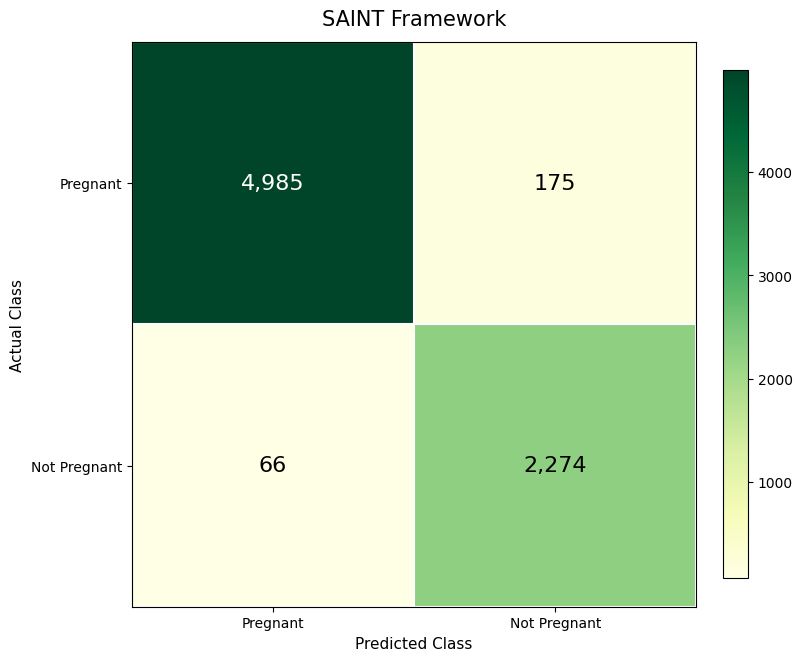

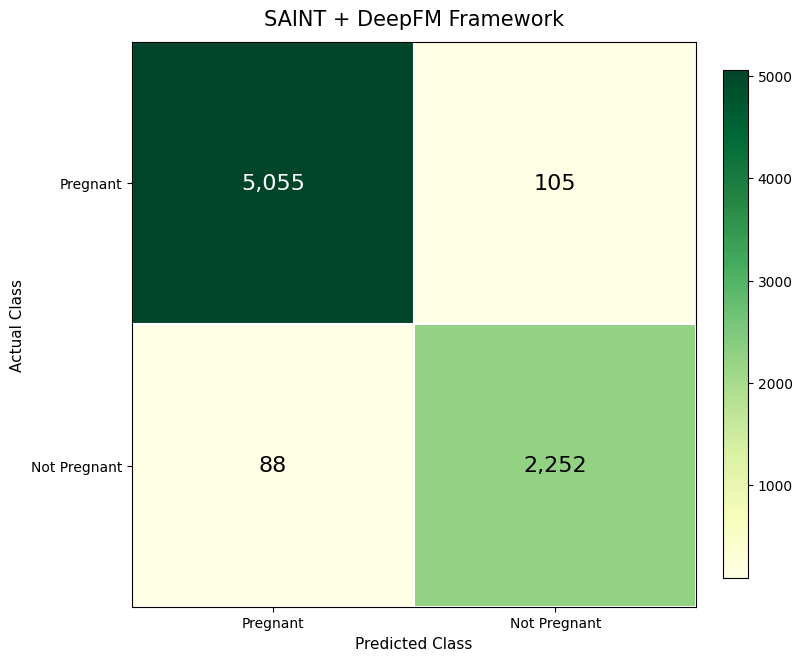

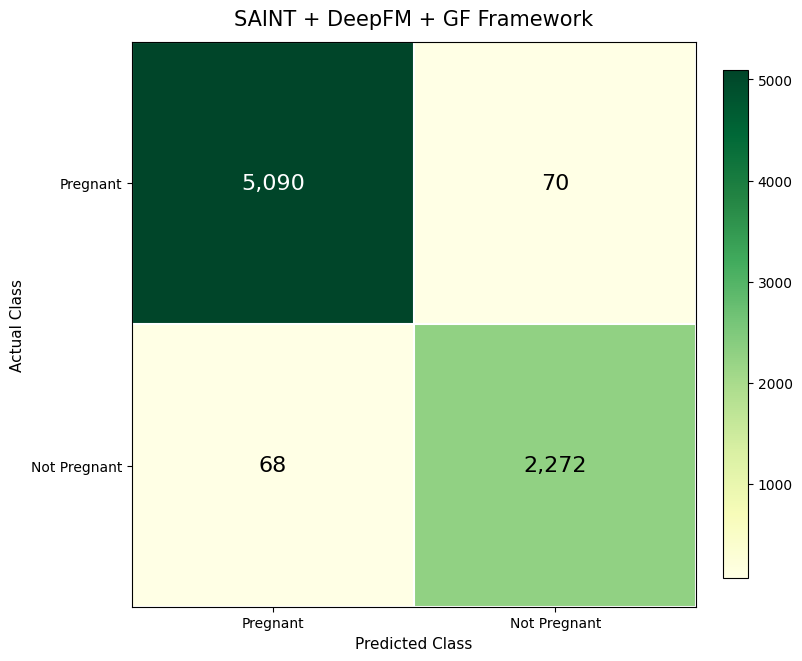

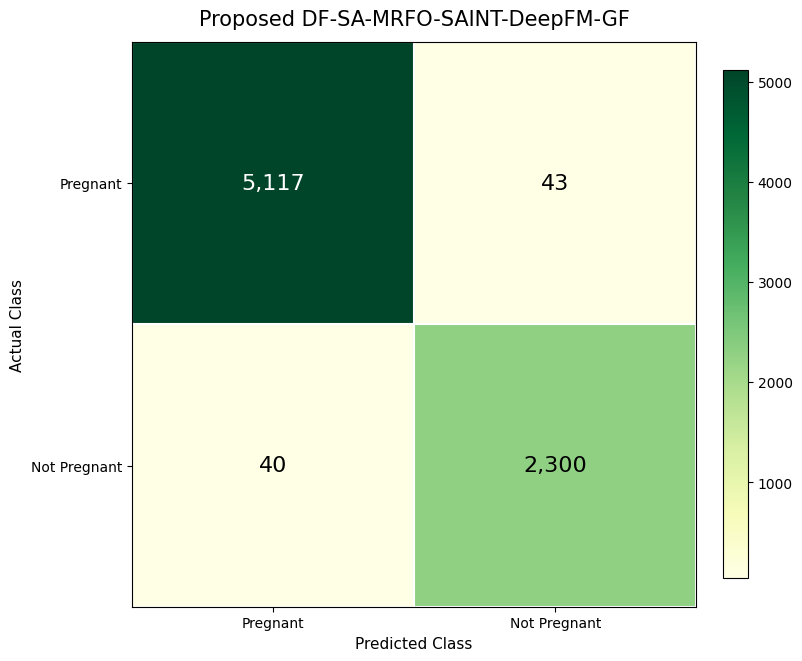

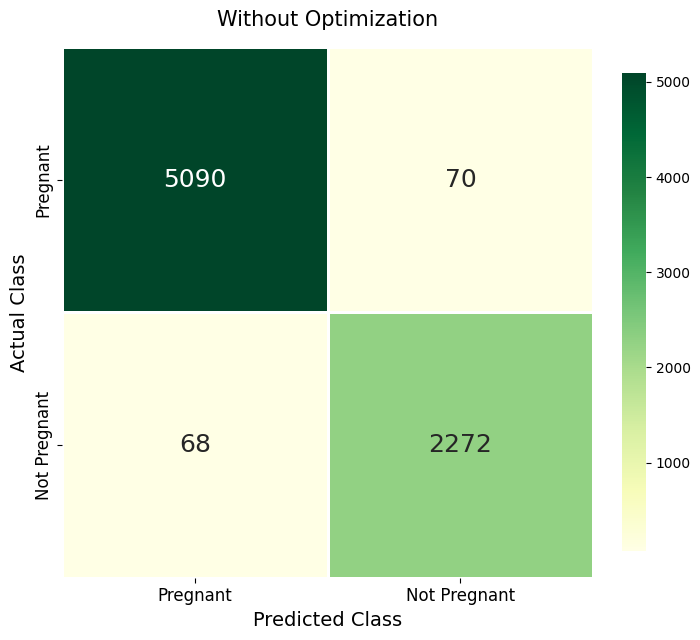

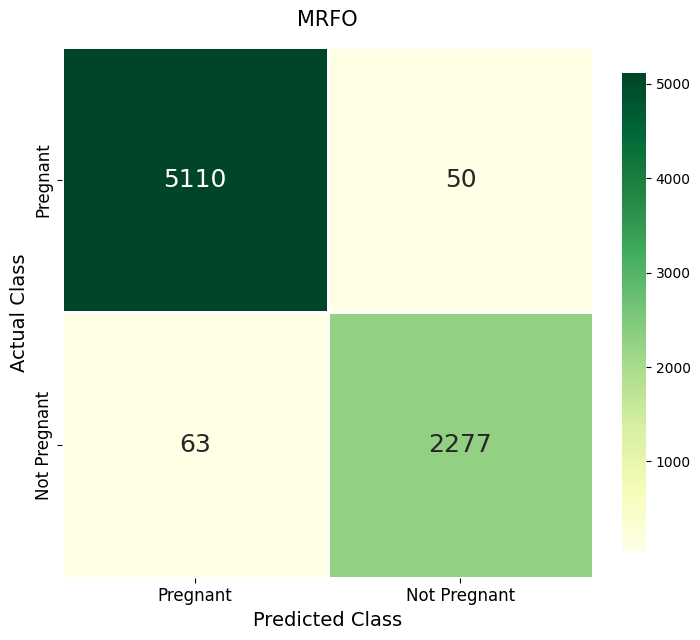

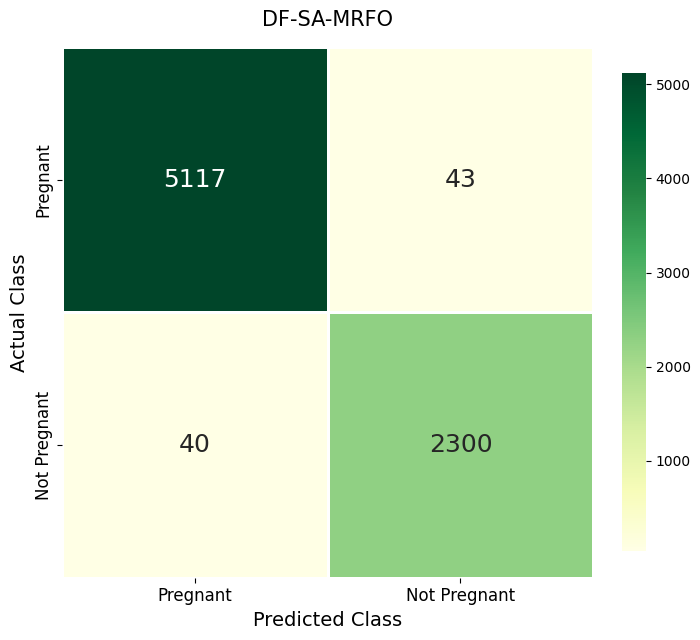

In [ ]:

LABELS = ["Pregnant", "Not Pregnant"]

def cm_array(r):                       # [[TP, FN], [FP, TN]] with Pregnant as the first row/column
    return np.array([[r["TP"], r["FN"]], [r["FP"], r["TN"]]])

def plot_cm(key, title, fname):
    if key not in ABL: return
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm_array(ABL[key]), annot=True, fmt="d", cmap="Greens", cbar=True,
                xticklabels=LABELS, yticklabels=LABELS, linewidths=1, linecolor="white",
                annot_kws={"fontsize": 16, "fontweight": "normal"})
    plt.xlabel("Predicted Class", fontsize=13); plt.ylabel("Actual Class", fontsize=13)
    plt.title(title, fontsize=12); plt.xticks(rotation=0); plt.yticks(rotation=0)
    save_fig(fname)

plot_cm("saint",  " SAINT framework",                "cm_saint.png")
plot_cm("concat", " SAINT + DeepFM Framework",       "cm_saint_deepfm.png")
plot_cm("gate",   "SAINT + DeepFM + GF Framework",  "cm_saint_deepfm_gf.png")

plot_cm("gate",   "Without optimization", "cm_no_optimization.png")
plot_cm("mrfo",   "MRFO",                 "cm_mrfo.png")

plot_cm("dfsamrfo", "DF-SA-MRFO",              "cm_dfsamrfo.png")

## Gate analysis

Per-record mean gate value
Overall: mean=0.587, SD=0.122, percentiles=[0.377 0.5   0.593 0.676 0.778]
Pregnant: mean=0.598, SD=0.120, percentiles=[0.388 0.513 0.605 0.686 0.783]
Not Pregnant: mean=0.562, SD=0.123, percentiles=[0.355 0.476 0.565 0.652 0.76 ]
Mann–Whitney U-test p-value = 1.873e-30


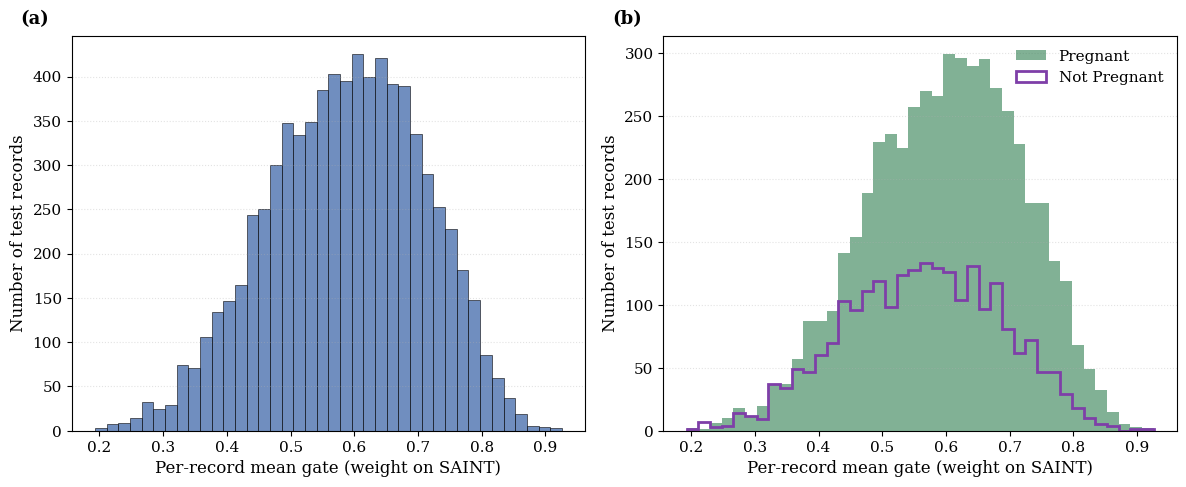

In [ ]:
gm = ABL.get(GATE_MODEL_KEY)

if gm is None or gm["model"] is None:
    print(f"Gate analysis skipped: model '{GATE_MODEL_KEY}' was not trained / kept.")

else:
    G = np.asarray(
        predict_gate(gm["model"], Xc_te, Xk_te, gm["hp"]["batch_size"])
    )
    Y = np.asarray(y_test).astype(int).ravel()

    if G.ndim != 2:
        raise ValueError(f"Expected 2D gate output (N, d), got shape {G.shape}")
    if G.shape[0] != len(Y):
        raise ValueError("Gate output count does not match test labels.")
    if not np.isin(Y, [0, 1]).all():
        raise ValueError("y_test must contain labels 0 and 1.")

    # Mean gate value per record
    pm = G.mean(axis=1)
    g_preg = pm[Y == 1]
    g_not = pm[Y == 0]
    pct = [5, 25, 50, 75, 95]

    # ---------------- Printed output ----------------
    print("Per-record mean gate value")
    print(
        f"Overall: mean={pm.mean():.3f}, SD={pm.std(ddof=1):.3f}, "
        f"percentiles={np.percentile(pm, pct).round(3)}"
    )
    for values, name in [(g_preg, "Pregnant"), (g_not, "Not Pregnant")]:
        if len(values) == 0:
            print(f"{name}: No records available.")
            continue
        print(
            f"{name}: mean={values.mean():.3f}, SD={values.std(ddof=1):.3f}, "
            f"percentiles={np.percentile(values, pct).round(3)}"
        )

    if len(g_preg) > 0 and len(g_not) > 0:
        p_value = mannwhitneyu(g_preg, g_not, alternative="two-sided").pvalue
        print(f"Mann\u2013Whitney U-test p-value = {p_value:.3e}")

    # ---------------- Plots ----------------
    bins = np.linspace(pm.min(), pm.max(), 41)
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # (a) Overall gate distribution
    ax[0].hist(pm, bins=bins, color="#4C72B0", edgecolor="black", linewidth=0.5, alpha=0.8)
    ax[0].set_xlabel("Per-record mean gate (weight on SAINT)")
    ax[0].set_ylabel("Number of test records")
    ax[0].grid(axis="y", linestyle=":", alpha=0.35)
    ax[0].set_axisbelow(True)

    # (b) Gate distribution by pregnancy outcome
    ax[1].hist(g_preg, bins=bins, color="#2E7D4F", alpha=0.6, label="Pregnant")
    ax[1].hist(g_not, bins=bins, histtype="step", linewidth=2, color="#7E3FA8", label="Not Pregnant")
    ax[1].set_xlabel("Per-record mean gate (weight on SAINT)")
    ax[1].set_ylabel("Number of test records")
    ax[1].legend(frameon=False)
    ax[1].grid(axis="y", linestyle=":", alpha=0.35)
    ax[1].set_axisbelow(True)

    ax[0].text(-0.10, 1.03, "(a)", transform=ax[0].transAxes, fontsize=13, fontweight="bold")
    ax[1].text(-0.10, 1.03, "(b)", transform=ax[1].transAxes, fontsize=13, fontweight="bold")

    plt.tight_layout()
    plt.savefig("gate_distribution_combined.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


In [1]:
# share of total gate variance explained by differences between records
total_var   = G.var()                    # variance over all N x d gate values
between_var = G.mean(axis=1).var()       # variance of the per-record means
print(f"Between-record share of gate variance: {between_var / total_var * 100:.1f}%")

Between-record share of gate variance: 73.4%
